<a href="https://colab.research.google.com/github/Hema392/ITA0314-Mobile-Computing-/blob/main/Exp_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


EXPERIMENT 16: FREE-SPACE PATH LOSS AND RECEIVED POWER

Frequency = 900 MHz
  d (km)   FSPL (dB)   Pr (dBm)        Pr (W)
     0.1       71.52     -13.52     4.441e-05
     0.5       85.50     -27.50     1.777e-06
     1.0       91.52     -33.52     4.441e-07
     2.0       97.55     -39.55     1.110e-07
     5.0      105.50     -47.50     1.777e-08
    10.0      111.52     -53.52     4.441e-09

Frequency = 1800 MHz
  d (km)   FSPL (dB)   Pr (dBm)        Pr (W)
     0.1       77.55     -19.55     1.110e-05
     0.5       91.52     -33.52     4.441e-07
     1.0       97.55     -39.55     1.110e-07
     2.0      103.57     -45.57     2.776e-08
     5.0      111.52     -53.52     4.441e-09
    10.0      117.55     -59.55     1.110e-09


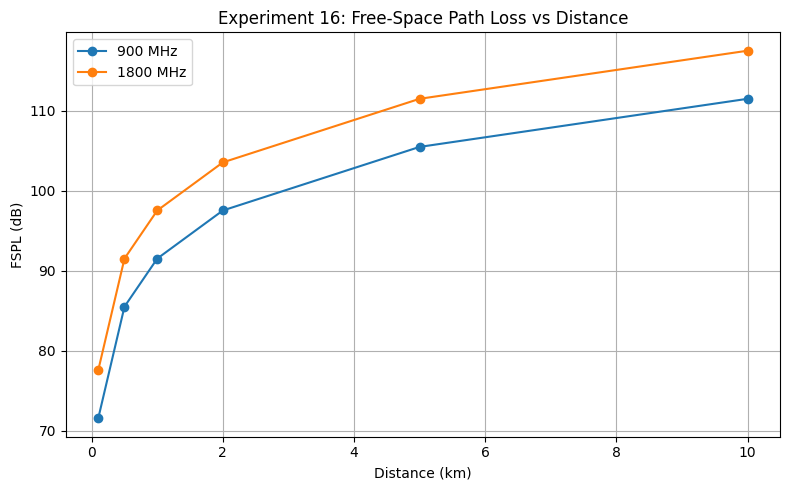

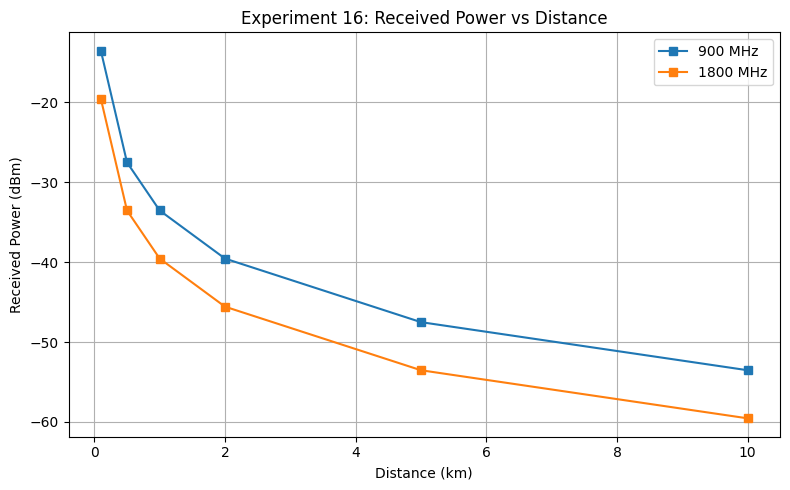

In [1]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt

OUT = "ITA03_Graphs"
os.makedirs(OUT, exist_ok=True)

def save_show(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT, name), dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

# EXPERIMENT 16: Free-Space Path Loss and Received Power
print("\n" + "="*72 + "\nEXPERIMENT 16: FREE-SPACE PATH LOSS AND RECEIVED POWER\n" + "="*72)
def fspl_db(d_km, f_mhz):
    return 20*np.log10(d_km) + 20*np.log10(f_mhz) + 32.44

Pt_dbm, Gt_db, Gr_db = 43.0, 15.0, 0.0
distances = np.array([0.1, 0.5, 1, 2, 5, 10], dtype=float)
freqs = [900, 1800]
results16 = {}
for f in freqs:
    print(f"\nFrequency = {f} MHz")
    print(f"{'d (km)':>8}{'FSPL (dB)':>12}{'Pr (dBm)':>11}{'Pr (W)':>14}")
    loss = fspl_db(distances, f)
    pr = Pt_dbm + Gt_db + Gr_db - loss
    pw = 10**(pr/10)/1000
    results16[f] = (loss, pr, pw)
    for d, l, p, w in zip(distances, loss, pr, pw):
        print(f"{d:8.1f}{l:12.2f}{p:11.2f}{w:14.3e}")

plt.figure(figsize=(8,5))
for f in freqs:
    plt.plot(distances, results16[f][0], marker="o", label=f"{f} MHz")
plt.xlabel("Distance (km)"); plt.ylabel("FSPL (dB)")
plt.title("Experiment 16: Free-Space Path Loss vs Distance")
plt.grid(True); plt.legend()
save_show("Exp16_FSPL_vs_Distance.png")

plt.figure(figsize=(8,5))
for f in freqs:
    plt.plot(distances, results16[f][1], marker="s", label=f"{f} MHz")
plt.xlabel("Distance (km)"); plt.ylabel("Received Power (dBm)")
plt.title("Experiment 16: Received Power vs Distance")
plt.grid(True); plt.legend()
save_show("Exp16_Received_Power_vs_Distance.png")